In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("/content/creditcard.csv")

In [3]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [4]:
df.shape

(284807, 31)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [6]:
df.isnull().sum()

,0
Time,0
V1,0
V2,0
V3,0
V4,0
V5,0
V6,0
V7,0
V8,0
V9,0


In [7]:
df.duplicated().sum()

np.int64(1081)

In [8]:
df["Class"].value_counts() #Class Imbalance

,count
Class,
0,284315
1,492


In [9]:
df.drop_duplicates(inplace=True)

In [10]:
df.duplicated().sum() #Verify no duplicate values are present

np.int64(0)

In [11]:
df['Class'].unique()

array([0, 1])

EDA
##Univariate analysis



In [12]:
import matplotlib.pyplot as plt
import numpy as np

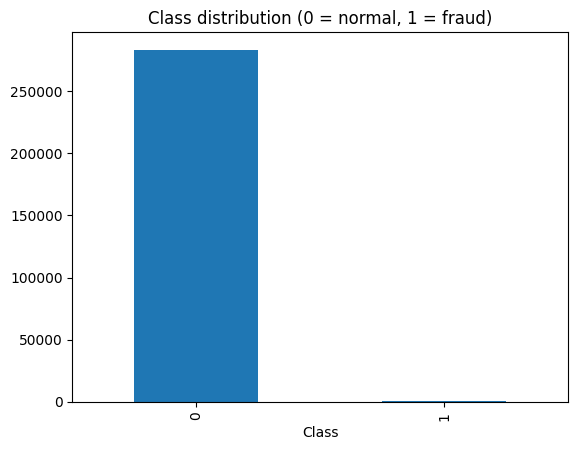

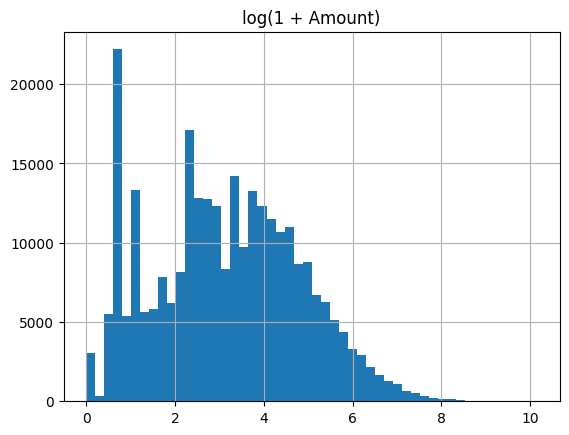

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,283253.0,88.413575,250.379023,0.0,5.67,22.00,77.46,25691.16
1,473.0,123.871860,260.211041,0.0,1.00,9.82,105.89,2125.87


In [13]:
df["Class"].value_counts().plot(kind="bar")
plt.title("Class distribution (0 = normal, 1 = fraud)")
plt.show()

np.log1p(df["Amount"]).hist(bins=50)
plt.title("log(1 + Amount)")
plt.show()

df.groupby("Class")["Amount"].describe()

the data is extremely imbalanced, and Amount is heavily skewed.

##Multivariate analysis


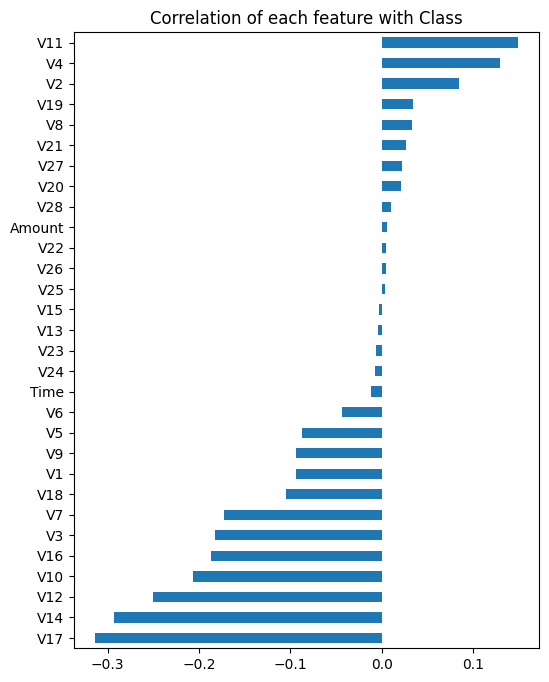

In [14]:
corr = df.corr()["Class"].drop("Class").sort_values()
corr.plot(kind="barh", figsize=(6, 8))
plt.title("Correlation of each feature with Class")
plt.show()

Data Preprocessing

In [15]:
df=df.dropna(subset=["Class"])

In [16]:
X = df.drop("Class",axis=1)
y = df["Class"]

Train-Test Split and Feature Scaling

In [17]:
from sklearn.model_selection import train_test_split

In [18]:
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42, stratify=y)

In [19]:
from sklearn.preprocessing import StandardScaler

In [20]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

Handling Imbalance data
#Here I use Under sampling

In [21]:
from imblearn.under_sampling import RandomUnderSampler

In [22]:
rus = RandomUnderSampler(random_state=42)
X_train_balanced, y_train_balanced = rus.fit_resample(X_train, y_train)

In [23]:
y_train_balanced.value_counts()

,count
Class,
0,355
1,355


Model Training, Testing and Evaluation
## Model1: Logistic regression


In [24]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(max_iter=1000)
model.fit(X_train_balanced, y_train_balanced)

LogisticRegression(max_iter=1000)

In [25]:
y_pred = model.predict(X_test)

Evaluation

In [26]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred)
print(cm)

[[67750  3064]
 [   11   107]]


Improvement:
Version2 because the precision of previous model was 3%
##Model2: Random Forest (undersampling 1:10)

In [27]:
from imblearn.under_sampling import RandomUnderSampler
rus = RandomUnderSampler(random_state=42, sampling_strategy = 0.1)
X_train_v2, y_train_v2 = rus.fit_resample(X_train, y_train)

In [28]:
y_train_v2.value_counts()

,count
Class,
0,3550
1,355


In [29]:
from sklearn.ensemble import RandomForestClassifier

In [30]:
model_v2 = RandomForestClassifier(random_state=42)

In [31]:
model_v2.fit(X_train_v2, y_train_v2)

RandomForestClassifier(random_state=42)

In [32]:
y_pred_v2 = model_v2.predict(X_test)

In [33]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred_v2)
print(cm)

[[70745    69]
 [   23    95]]


In [34]:
from sklearn.metrics import roc_auc_score, average_precision_score

proba_lr = model.predict_proba(X_test)[:, 1]
proba_rf = model_v2.predict_proba(X_test)[:, 1]

print("LogReg  ROC-AUC:", roc_auc_score(y_test, proba_lr), "| PR-AUC:", average_precision_score(y_test, proba_lr))
print("RF      ROC-AUC:", roc_auc_score(y_test, proba_rf), "| PR-AUC:", average_precision_score(y_test, proba_rf))

LogReg  ROC-AUC: 0.9742509979593235 | PR-AUC: 0.504869438661645
RF      ROC-AUC: 0.9742479462789365 | PR-AUC: 0.681972419430452


Both models have almost the same ROC-AUC (0.974), but their PR-AUC differs a lot (0.50 vs 0.68). So PR-AUC is the more reliable metric here.

## Model 3: XGBoost (full data, no undersampling)

In [35]:
from xgboost import XGBClassifier

X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.2, stratify=y_train, random_state=42)

xgb = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                    subsample=0.8, colsample_bytree=0.8,
                    eval_metric="aucpr", random_state=42, n_jobs=-1)
xgb.fit(X_tr, y_tr)

proba_val = xgb.predict_proba(X_val)[:, 1]
proba_test = xgb.predict_proba(X_test)[:, 1]
print("PR-AUC:", average_precision_score(y_test, proba_test))

PR-AUC: 0.8316625424464409


In [36]:
def evaluate(name, m, Xt, yt):
    m.fit(Xt, yt)
    pred = m.predict(X_test)
    proba = m.predict_proba(X_test)[:, 1]
    rows.append({"model": name,
                 "precision": precision_score(y_test, pred),
                 "recall": recall_score(y_test, pred),
                 "f1": f1_score(y_test, pred),
                 "pr_auc": average_precision_score(y_test, proba)})

In [37]:
from sklearn.metrics import PrecisionRecallDisplay

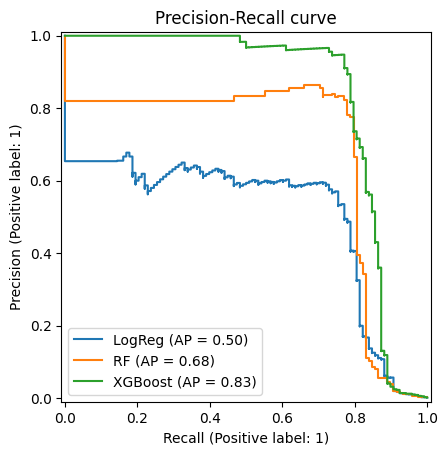

In [38]:
fig, ax = plt.subplots()
PrecisionRecallDisplay.from_predictions(y_test, proba_lr, name="LogReg", ax=ax)
PrecisionRecallDisplay.from_predictions(y_test, proba_rf, name="RF", ax=ax)
PrecisionRecallDisplay.from_predictions(y_test, proba_test, name="XGBoost", ax=ax)
plt.title("Precision-Recall curve")
plt.show()

In [39]:
from sklearn.metrics import precision_score, recall_score, f1_score

rows = []
evaluate("LogReg (undersample 1:1)", model, X_train_balanced, y_train_balanced)
evaluate("RF (undersample 1:10)", model_v2, X_train_v2, y_train_v2)
evaluate("XGBoost (full data)", xgb, X_tr, y_tr)

results = pd.DataFrame(rows)
results.round(3)

,model,precision,recall,f1,pr_auc
0,LogReg (undersample 1:1),0.034,0.907,0.065,0.505
1,RF (undersample 1:10),0.579,0.805,0.674,0.682
2,XGBoost (full data),0.947,0.754,0.840,0.832


XGBoost has the highest PR-AUC (0.83) and trains on the full data without undersampling.

## Threshold Tuning

In [40]:
from sklearn.metrics import precision_recall_curve

prec, rec, thr = precision_recall_curve(y_val, proba_val)
target_recall = 0.80
best_thr = thr[np.where(rec[:-1] >= target_recall)[0][-1]]

final_pred = (proba_test >= best_thr).astype(int)
print("threshold:", best_thr)
print(confusion_matrix(y_test, final_pred))
print("Precision:", precision_score(y_test, final_pred))
print("Recall:", recall_score(y_test, final_pred))
print("F1:", f1_score(y_test, final_pred))

threshold: 0.07054857
[[70792    22]
 [   24    94]]
Precision: 0.8103448275862069
Recall: 0.7966101694915254
F1: 0.8034188034188035


At the default threshold (0.5), XGBoost gives precision 0.95 and recall 0.75. Lowering the threshold to about 0.07, chosen on a validation set to reach 80% recall, catches 94 of 118 frauds with 22 false alarms (precision 0.81, F1 0.80). Pushing recall to 85% raises false alarms to several hundred, so I chose 80% as a balanced operating point.

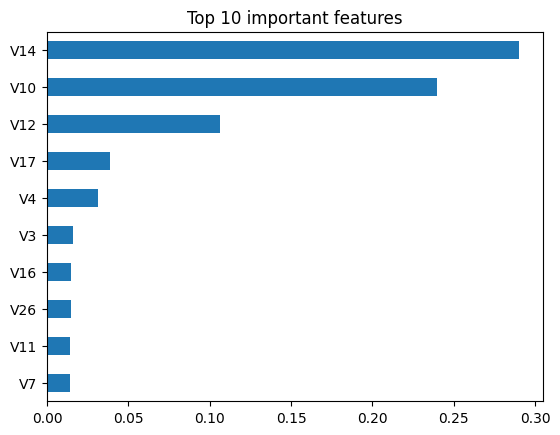

In [41]:
imp = pd.Series(xgb.feature_importances_, index=X.columns).sort_values().tail(10)
imp.plot(kind="barh")
plt.title("Top 10 important features")
plt.show()

In [43]:
import joblib

joblib.dump({"scaler": scaler, "model": xgb, "threshold": best_thr}, "fraud_model.joblib")

sample = pd.concat([df[df.Class == 1].sample(30, random_state=1),
                    df[df.Class == 0].sample(470, random_state=1)]).sample(frac=1, random_state=1)
sample.to_csv("sample_transactions.csv", index=False)

from google.colab import files
files.download("fraud_model.joblib")
files.download("sample_transactions.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Final model: XGBoost.
Final precision, recall aur F1 (Cell 4 ke 0.80 wale numbers).
Trade-off ki ek line.
Limitation: V1 se V28 anonymized hai.

In [44]:
#!pip list | grep -i -E "scikit-learn|xgboost|pandas|joblib" Delete after note